**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

In [1]:
import itertools as it
import re
import os
import warnings
warnings.simplefilter(category=FutureWarning, action='ignore')

import numpy as np
import pandas as pd
import scipy
from scipy.stats import studentized_range as q_dist
import seaborn as sn
import skbio
from skbio import OrdinationResults, DistanceMatrix
import patsy
import statsmodels.formula.api as smf
import statsmodels.api as sms

from matplotlib import rcParams
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.image as mpimg

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.diversity.actions as q2_div
import qiime2.plugins.longitudinal.actions as q2_longitudinal
import qiime2.plugins.taxa.actions as q2_taxa


import scripts.alpha_plots as ap
import scripts.bl_plot as bp
from scripts.extract_fits import (extract_period_fits,
                                  extract_abxbl_fit,
                                  extract_recovery_fits,
                                  build_tidy_str,
                                  find_abx,
                                 )

# from scripts.arg_lme import fit_full_lme

from IPython.display import HTML

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
hide_axes = dict(left=False, labelleft=False,
                 right=False, labelright=False,
                 length=0,
                 labelsize=0)

In [3]:
%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42
np.set_printoptions(precision=5)


In [4]:
abx_order = ['untreated', 'nitrofurantoin', 'pivmecillinam',
             'co-trimoxazole', 'ceftibuten', 'ciprofloxacin']
colors = ['#969696', '#009E73','#9D654C', 
          '#4E7705', '#098BD9',  '#CC79A7']
spectrum_order = ['untreated', 'narrow', 'broad']
alpha_metrics = ['observed_features', 'shannon', 'simpson']
abx_names = {str(i): abx for i, abx in enumerate(abx_order)}
abx_colors = {str(i): color for i, color in enumerate(colors)}

In [5]:
clean_metrics = {'observed_features': 'Observed Species',
                 'unweighted_unifrac': 'unweighted\nUniFrac',
                 'weighted_unifrac': 'weighted\nUniFrac',
                 'braycurtis': 'Bray Curtis',
                 'rpca': 'rPCA\nAitchison',
                 'phylo_rpca': 'phylo rPCA\nAitchison'
                 }


# Figure layout

In [6]:
def _label_panel(fig, label):
    """
    Lazy function to label panels
    """
    ax = fig.add_subplot(1,1,1)
    ax.xaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(**hide_axes)
    ax.text(0.5, 0.5, label, ha='center', va='center', size=10)

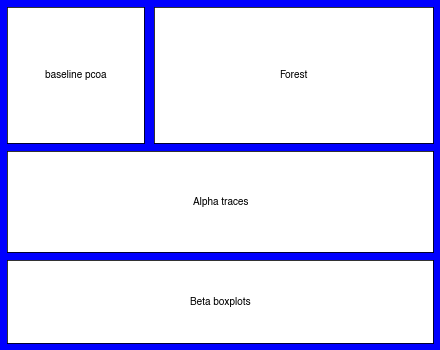

In [7]:
fig = plt.figure(dpi=72, constrained_layout=True, figsize=(6, 4.75), facecolor='blue')
[fig0, fig1, fig2] = fig.subfigures(3, 1, height_ratios=[2, 1.5, 1.25], facecolor='None')
[fig01, fig02] = fig0.subfigures(1, 2, width_ratios=[2, 4], facecolor='None')
_label_panel(fig01, 'baseline pcoa')
_label_panel(fig02, 'Forest')
_label_panel(fig1, 'Alpha traces')
_label_panel(fig2, 'Beta boxplots')

# Data

## Overall

### Metadata

In [8]:
meta_all = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta_all.set_index('sample-id', inplace=True)
meta_all[['age', 'days_since_intervention', 'gtdb_depth']] = \
    meta_all[['age', 'days_since_intervention', 'gtdb_depth']].astype(float)

meta = meta_all[['host_subject_id', 'timepoint', 'days_since_intervention',
             'abx_code2', 'age', 'sex', 'vegetarian', 'extraction_no', 'after_travel_na_eu']].copy()

### Alpha Diversity

In [9]:
alpha_dir = 'final-data/04.alpha-diveristy'
alpha_metrics = ['observed_features', 'shannon', 'simpson']
alpha_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg.qza')
    for metric in alpha_metrics
    }

### Beta Diversity

In [10]:
classic_beta_dir = 'final-data/06.beta-diveristy/'
dm_fps = {fp_.split('_1M')[0]: f'{classic_beta_dir}/{fp_}'
          for fp_ in os.listdir(classic_beta_dir) 
          if ('dm.qza' in fp_) and ('unifrac' in fp_)
          }

dms_q2 = {metric: Artifact.load(fp_) for metric, fp_ in dm_fps.items()}

## Baseline

For our baseline, we're going to put in a PCoA of beta dviersity. I originally had the rPCA (whcih I liked) but I think we're going to switch to unweighted UniFrac for consistency.

In [11]:
meta_bl = meta.loc[meta['timepoint'].isin([0, '0', '0.0'])].copy()
dm_bl_q2 = {
    metric: q2_div.filter_distance_matrix(dm_q2, metadata=Metadata(meta_bl))
    for metric, dm_q2 in dms_q2.items()
    if 'rpca' not in metric
}
dm_bl_q2 = {metric: res.filtered_distance_matrix 
            for metric, res in dm_bl_q2.items()}
pc_bl_q2 = {metric: q2_div.pcoa(dm_q2, number_of_dimensions=5).pcoa
            for metric, dm_q2 in dm_bl_q2.items()
            }

In [12]:
taxa_adonis = pd.read_csv('final-data/06.baseline_compare/adonis_res.tsv',
                          sep='\t',
                          dtype=str)
taxa_adonis[['R2', 'p_value']] = taxa_adonis[['R2', 'p_value']].astype(float)
taxa_adonis['nperm'] = taxa_adonis['nperm'].astype(int)
taxa_adonis.set_index(['metric', 'model', 'key_vars'], inplace=True)


In [13]:
abrev = {'braycurtis': 'bc',
         'unweighted_unifrac': 'uu',
         'weighted_unifrac': 'wu',
         'jaccard': 'jc',
          }
bl_coords = [meta_bl]
bl_coords.extend(
    [pc.view(OrdinationResults).samples.add_prefix(abrev[metric])
    for metric, pc in pc_bl_q2.items()]
)
bl_coords = pd.concat(axis=1, objs=bl_coords)
bl_coords['uu0'] = bl_coords['uu0'] * np.sign(bl_coords.loc['17-669', 'uu0'])
bl_coords['uu1'] = bl_coords['uu1'] * np.sign(bl_coords.loc['17-074', 'uu1'])


bl_perc_exp = pd.concat(axis=0, objs=[
    pc.view(OrdinationResults).proportion_explained.add_prefix(abrev[metric])
    for metric, pc in pc_bl_q2.items()])

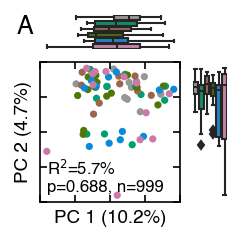

In [14]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(1.5, 1.5))

def make_bl_ordination(fig, xx, yy, metric, model):
    """
    Makes the baseline PCoA figure
    """

    bp.plot_ordination(fig, xx, yy, 'abx_code2', abx_colors, 
                       bl_coords, bl_perc_exp, 
                       scatter_kws=dict(s=12),
                       box_kws=dict(linewidth=1, fliersize=3)
                       )
    fig.axes[0].xaxis.get_label().set_size(9)
    fig.axes[0].yaxis.get_label().set_size(9)
    bl_str = 'R$^{{2}}$={R2:1.1%}\np={p_value:1.3f}, n=999'.format(
        **taxa_adonis.loc[(metric, model, 'abx')])
    fig.axes[0].text(
        x=fig.axes[0].get_xlim()[0] + 0.05 * np.diff(fig.axes[0].get_xlim()),
        y=fig.axes[0].get_ylim()[0] + 0.05 * np.diff(fig.axes[0].get_ylim()),
        s=bl_str,
        ha='left',
        va='bottom',
        size=8)
    fig.axes[1].text(
        x=fig.axes[1].get_xlim()[0] - np.diff(fig.axes[1].get_xlim()) * 0.05,
        y=fig.axes[1].get_ylim()[1],
        s='A', 
        ha='right', va='top', size=12
    )

make_bl_ordination(fig, 'uu0', 'uu1', 'unweighted_unifrac', 'full')

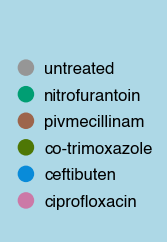

In [15]:
figl = plt.figure(dpi=150, constrained_layout=True, figsize=(1, 1.5), facecolor='lightblue')
def _make_legend(figl):
    """
    Helper function to make a legend for hte baseline data incase people 
    can't read common color palettes
    """
    ax = figl.add_subplot(1,1,1, facecolor='None')
    ax.scatter(x=np.zeros(6), y=5-np.arange(6), c=colors, marker='o', s=48)
    ax.set_ylim(-1, 7)
    ax.set_yticks(5-np.arange(6))
    ax.set_yticklabels(abx_order)
    ax.xaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(left=False, right=False, length=0,
                             labelleft=False, labelright=True, labelsize=8)
    sn.despine(ax=ax, left=True, right=True, top=True, bottom=True)

_make_legend(figl)

## Within participant change

Since we're dropping the experimental deisgn panel, and we have more space, we're going to bring in the within-participant changes to hammer home why we're looking at the diversity within an individual.

In [16]:
dm_long = {metric: dm_q2.view(DistanceMatrix).filter(meta.index)
           for metric, dm_q2 in dms_q2.items()}
dm_long = pd.DataFrame({metric: dm.to_series() 
                        for metric, dm in dm_long.items()})
dm_long.index.set_names(['sample0', 'sample1'], inplace=True)
dm_long.reset_index(inplace=True)
dm_long['subject0'] = \
    meta.loc[dm_long['sample0'], 'host_subject_id'].reset_index(drop=True)
dm_long['subject1'] = \
    meta.loc[dm_long['sample1'], 'host_subject_id'].reset_index(drop=True)
dm_long['plate0'] = \
    meta.loc[dm_long['sample0'], 'extraction_no'].reset_index(drop=True)
dm_long['plate1'] = \
    meta.loc[dm_long['sample1'], 'extraction_no'].reset_index(drop=True)
dm_long['abx0'] = \
    meta.loc[dm_long['sample0'], 'abx_code2'].reset_index(drop=True)
dm_long['abx1'] = \
    meta.loc[dm_long['sample1'], 'abx_code2'].reset_index(drop=True)
dm_long['same_subject'] = dm_long['subject0'] == dm_long['subject1']
dm_long['same_plate'] = dm_long['plate0'] == dm_long['plate1']
dm_long['same_antibiotic'] = dm_long['abx0'] == dm_long['abx1']
dm_long['matched'] = dm_long[['same_plate', 'same_antibiotic']].all(axis=1)
dm_long.loc[dm_long['matched'], 'compare'] = 'between'
dm_long.loc[dm_long['same_subject'], 'compare'] = 'within'

In [17]:
from scipy.stats import ttest_ind
def permutative_t_test(metric, grouper, data, nperm=999):
    """
    Performs a permutative t-test
    """
    summary = pd.DataFrame(
        data=np.vstack([
            np.random.permutation(data[metric]) for i in range(nperm)
        ]).T,
        index=data.index
    )
    summary['reference'] = data[metric]
    summary['group'] = data[grouper]
    summary.set_index('group', inplace=True)
    grouped = summary.groupby('group')
    
    t_stat = pd.Series({
        col: ttest_ind(*grouped[col].apply(lambda x: x.values).values, equal_var=False)[0]
        for col in summary.columns
    })
    ref_val = t_stat['reference']
    t_stat = t_stat * np.sign(ref_val)
    p_val = (t_stat >= ref_val * np.sign(ref_val)).mean()
    
    return ref_val, p_val, nperm

In [18]:
perm_summary = {
    metric: permutative_t_test(metric=metric, grouper='compare', data=dm_long)
    for metric in dms_q2.keys()
}
perm_summary

{'unweighted_unifrac': (38.90252366940855, 0.001, 999),
 'weighted_unifrac': (21.44965158074048, 0.001, 999)}

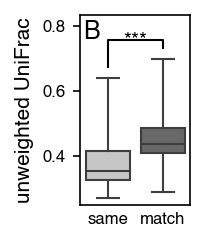

In [19]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(1.25, 1.5))
def plot_compare_boxplot(fig, metric, letter):
    """
    Shows the within vs matched comparisons
    """
    ax = fig.add_subplot(1,1,1)
    ax.yaxis.set_tick_params(left=True, labelleft=True,
                             right=False, labelright=False,
                             labelsize=8)
    ax.xaxis.set_tick_params(bottom=False, labelbottom=True, top=False, 
                             labeltop=False, labelsize=8, length=0)
    metric = 'unweighted_unifrac'
    
    sn.boxplot(ax=ax,
               x='compare', 
               y=metric, 
               data=dm_long,
               order=['within', 'between'],
               palette='Grays',
               whis=3,
               fliersize=1,
               flierprops=dict(marker='o', markerfacecolor='None'),
               linewidth=1,
               )
    ltops = dm_long.groupby('compare')[metric].max()
    ydelta = np.diff(ax.get_ylim())
    ax.set_ylim(ax.get_ylim()[0], ax.get_ylim()[0] + ydelta * 1.25)
    
    ax.xaxis.get_label().set_visible(False)
    ax.set_ylabel(clean_metrics.get(metric, metric.title()).replace('\n', ' '), 
                  size=10)
    ax.plot([0, 0, 1, 1], 
            [ltops['within'] + 0.075 * ydelta, ltops.max() + 0.125 * ydelta, 
             ltops.max() + 0.125 * ydelta, ltops['between'] + 0.075 * ydelta],
             linewidth=1,
             color='k',
             )
    p_val = perm_summary[metric][1]
    ax.text(0.5, ltops.max() + 0.125 * ydelta, 
                ''.join(['*'] * int(np.floor(-np.log10(p_val)))),
                ha='center',
                va='center'
                )
    ax.set_xticklabels(['same', 'match'])
    ax.text(ax.get_xlim()[0] + np.diff(ax.get_xlim()) * 0.025, 
            ax.get_ylim()[1] + np.diff(ax.get_ylim()) * -0.025, 
            letter, ha='left', va='top', size=12)
plot_compare_boxplot(fig, 'unweighted_unfirac', 'B')

## Follow up

### Alpha Diversity

In [20]:

meta_a = pd.DataFrame({metric: art.view(pd.Series) 
                       for metric, art in alpha_q2.items()})
meta_a[['host_subject_id', 'timepoint']] = meta[['host_subject_id', 'timepoint']]
meta_a.sort_values(['host_subject_id', 'timepoint'], ascending=True, inplace=True)
meta_a0 = meta_a.groupby('host_subject_id').first()[alpha_metrics]
alpha0 = meta_a0.loc[meta_a['host_subject_id'], alpha_metrics]
alpha0.index = meta_a.index

In [21]:
a_traces_q2 = {
    metric: Artifact.load(f'{alpha_dir}/{metric}_1M_avg_from_baseline.qza')
    for metric in np.hstack([alpha_metrics, 'depth'])
    }
a_traces = pd.DataFrame(
    {metric: art.view(pd.Series) for metric, art in a_traces_q2.items()
     if metric in alpha_metrics}
)

## Beta Diversity

In [22]:
trace_kwargs = dict(metadata=Metadata(meta),
                                state_column='timepoint',
                                individual_id_column='host_subject_id',
                                baseline=0)
b_traces_q2 = {
    metric: q2_longitudinal.first_distances(dm_q2, **trace_kwargs).first_distances
    for metric, dm_q2 in dms_q2.items()
}
b_traces = pd.DataFrame({metric: trace_q2.view(pd.Series) 
                         for metric, trace_q2 in b_traces_q2.items()})

## Combined data

In [23]:
meta_t = pd.concat(
    axis=1, 
    objs=[meta,
          a_traces_q2['depth'].view(pd.Series).to_frame().rename(columns={'Difference': 'depth_d'}) / 1e5,
          (a_traces / alpha0 * 100), 
          alpha0.add_suffix('_0'),
          (alpha0 > meta_a0.mean()).add_suffix('_0_cat') * 1,
          b_traces,
         ]
    )
meta_t.replace({metric: {np.nan: 0} for metric in alpha_metrics},
              inplace=True)
meta_t.sort_values(['abx_code2', 'host_subject_id', 'timepoint'],
                   ascending=True, inplace=True)
meta_t['first_extraction'] = \
    meta_t['host_subject_id'].replace(meta_t.groupby('host_subject_id')['extraction_no'].first())
meta_t['extr_not0'] = (meta_t['extraction_no'] != meta_t['first_extraction']) * 1
meta_t['days_inv'] = 30 / meta_t['days_since_intervention']
meta_t['abx_code2'] = meta_t['abx_code2'].astype(int)
meta_t['period'] = (meta_t['timepoint'].astype(float) > 0) * 1 + \
    (meta_t['timepoint'].astype(float) > 3) * 1

# Modeling

In [24]:
meta_r = meta_t.loc[~meta_t['timepoint'].isin(['0.0'])].copy()
meta_r['abx_bl'] = meta_r['abx_code2'].astype(int) * 10 + meta_r['period']
meta_r['unweighted_unifrac_scl'] = meta_r['unweighted_unifrac'] * 10

In [25]:
ref_eqs = {'model 2': ('depth_d + C(extraction_no) + after_travel_na_eu')}

## Alpha Modeling

We model alpha diveristy with a perturbation-recovery model.

In [26]:
fit_untreat = {
    (metric, model, rs_slope, '0'): smf.mixedlm(
        f'{metric} ~ C(abx_code2)*days_inv + {ref_eq}',
        data=meta_r,
        re_formula=re_formula,
        groups='host_subject_id'
        ).fit()
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1'])
    for metric in ['observed_features']
    }
fit_unt_params = \
    pd.concat([extract_recovery_fits(fit_, *keys) 
               for keys, fit_ in fit_untreat.items()])
fit_unt_params.set_index(['metric', 'slope', 'model', 'rs_slope', 
                          'ref_value', 'abx_code'],
                         inplace=True)

In [31]:
posthoc_dir = 'final-data/04.alpha-diveristy/post-hoc-fits'
os.makedirs(posthoc_dir, exist_ok=True)
meta_r.to_csv(f'{posthoc_dir}/alpha_trace.tsv', sep='\t')

In [32]:
%%bash
Rscript scripts/emmeans_posthoc/alpha_lmer_posthoc.R

There were 42 warnings (use warnings() to see them)
There were 42 warnings (use warnings() to see them)


In [33]:
os.listdir(posthoc_dir)

['alpha_trace.tsv', 'alpha_expanded_est.tsv', 'alpha_expanded_contrasts.tsv']

In [34]:
fit_unt_exp = \
    pd.read_csv(f'{posthoc_dir}/alpha_expanded_est.tsv',
                sep='\t', dtype=str)
fit_unt_exp['slope'] = fit_unt_exp['kind'].isin(['m']) * 1
fit_unt_exp.set_index(['metric', 'model', 'rs', 'slope', 'abx_code2'], 
                      inplace=True)
fit_unt_exp.drop(columns=['kind'], inplace=True)
fit_unt_exp.rename(columns={'lower.CL': 'ci_lo', 'upper.CL': 'ci_hi'},
                   inplace=True)
fit_unt_exp = fit_unt_exp.astype(float)
fit_unt_exp['width'] = fit_unt_exp['ci_hi'] - fit_unt_exp['beta']


## Alpha Plots

In [35]:
days = np.hstack([np.arange(1, 15, 1),
                  np.arange(15, 30, 3),
                  np.arange(30, 90, 15),
                  np.arange(90, 400, 30),
                 ])
predicted_alpha = ap.build_timing_grid(days, fit_unt_exp)

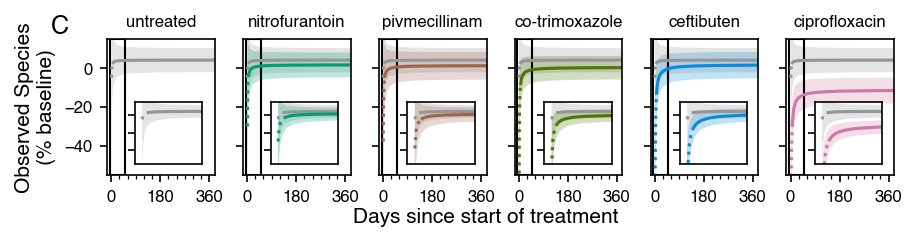

In [36]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 1.5))
sub_data = predicted_alpha.xs('observed_features', level='metric')
sub_data = sub_data.xs('model2', level='model')
sub_data = sub_data.xs('re', level='rs')
ap.plot_alpha_curve_row(fig, 'observed_features', sub_data, label='C')

In [37]:
sub_fit = fit_unt_params.copy()
sub_fit.reset_index(level=['metric', 'model', 'rs_slope'],
                    inplace=True,
                    drop=True)
sub_fit.reset_index(inplace=True)
sub_fit['tidy'] = sub_fit.apply(build_tidy_str, axis=1)
sub_fit['width'] = sub_fit['ci_hi'] - sub_fit['params']

# Masks the reference values
ref_idx = sub_fit['abx_code'] == sub_fit['ref_value']
sub_fit['params'] = sub_fit['params'].mask(ref_idx, 0)
sub_fit['width'] = sub_fit['width'].mask(ref_idx, np.nan)
sub_fit['p_value'] = sub_fit['p_value'].mask(ref_idx, 1)

sub_fit['marker'] = 's'
sub_fit['color'] = sub_fit['abx_code'].replace(abx_colors)
sub_fit['facecolor'] = sub_fit['color'].mask(sub_fit['p_value'] >= 0.05, 'w')
sub_fit['y'] = 5 - sub_fit['abx_code'].astype(int)

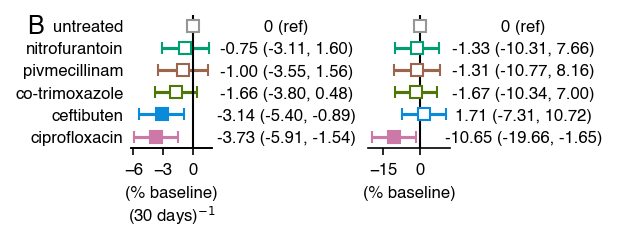

In [38]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(4, 1.5))
def _build_baseline(fig):
    """
    Builds a forestplot with teh alpha diveristy effect
    """
    forest_kwargs = dict(x='params', 
                         xerr='width', 
                         y='y', 
                         capsize=3,
                         linestyle='',    
                         )
    ax0 = fig.add_subplot(1, 2, 1)
    ax1 = fig.add_subplot(1, 2, 2)
    for ax_, (slope, df_) in zip(*([ax1, ax0], sub_fit.groupby('slope'))):
        for (m, c, fc), bdf in df_.groupby(['marker', 'color', 'facecolor']):
            ax_.errorbar(data=bdf,
                         color=c,
                         markerfacecolor=fc,
                         marker=m,
                         **forest_kwargs
                         )
        ax_.plot([0, 0], [-0.5, 5.5], linestyle='-', color='k', linewidth=1)
        ax_.set_ylim(-0.5, 5.5)
        ax_.set_yticks(df_['y'], minor=False)
        ax_.set_yticklabels(df_['tidy'], ha='center', minor=False)
        ax_.yaxis.set_tick_params(left=False, labelleft=False, 
                                  right=False, labelright=True, 
                                  labelsize=8, length=32, 
                                  which='major')
        ax_.xaxis.set_tick_params(bottom=True, labelbottom=True,
                                  top=False, labeltop=False,
                                  labelsize=8)
        ax_.xaxis.set_major_locator(ticker.MaxNLocator(3))
    axt = ax0.twinx()
    axt.set_ylim(ax0.get_ylim())
    axt.set_yticks(ax0.get_yticks())
    axt.set_yticklabels(abx_order)
    axt.yaxis.set_tick_params(left=False, labelleft=True, right=False, 
                              labelright=False, labelsize=8, length=0)
    ax0.yaxis.set_tick_params(left=False, labelleft=False, right=False, 
                              labelright=True)
    sn.despine(fig, left=True, right=True, top=True, bottom=False)
    ax0.set_xlabel('(% baseline)\n(30 days)$^{-1}$', size=8)
    ax1.set_xlabel('(% baseline)', size=8)

    ax0.text(ax0.get_xlim()[0] - np.diff(ax0.get_xlim()) - 2.25,
             ax0.get_ylim()[1],
             'B', size=12, ha='left', va='top')
    # ap._plot_betas(ax0, sub_fit.loc[sub_fit['slope']], 0, 0)
    # ap._plot_betas(ax1, sub_fit.loc[~sub_fit['slope']], 0, 0)

_build_baseline(fig)

## Beta modeling

In [39]:
beta_metrics = ['unweighted_unifrac']
for metric in beta_metrics:
    meta_r[f'{metric}_sc'] = meta_r[metric] * 10

In [40]:
fit_untreat = {
    (metric, model, rs_slope, '0'): smf.mixedlm(
        f'{metric}_sc ~ C(abx_code2)*C(period) + {ref_eq}',
        data=meta_r,
        re_formula=re_formula,
        groups='host_subject_id'
        ).fit()
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~ C(period)'])
    for metric in beta_metrics
    }
fit_unt_i_params = pd.concat(
    axis=0, 
    objs=[extract_period_fits(fit_, *keys)
          for keys, fit_ in fit_untreat.items()]
    )

In [41]:
period_fits = {
    (metric, model, rs_slope, '0', period): smf.mixedlm(f'{metric}_sc ~ C(abx_code2) + {ref_eq}',
                                                   data=period_df,
                                                   re_formula=re_formula,
                                                   groups='host_subject_id').fit()
    for period, period_df in meta_r.groupby('period')
    for model, ref_eq in ref_eqs.items()
    for rs_slope, re_formula in enumerate(['~1', '~ C(period)'])
    for metric in beta_metrics
}
period_params = pd.concat(
    axis=0, 
    objs=[extract_period_fits(fit_, metric, model, rs_slope, ref_value, period=period)
          for (metric, model, rs_slope, ref_value, period), fit_ in period_fits.items()]
)
period_params.set_index(['metric', 'model', 'rs_slope', 'period', 'abx_code'],
                        inplace=True)
period_params.sort_index(ascending=True, inplace=True)

In [42]:
period_pvals = period_params['p_value'].copy().xs('model 2', level='model')
period_pvals.drop(index=[1], level='rs_slope', inplace=True)
period_pvals.drop(['0'], level='abx_code', inplace=True)
period_pvals.mask((period_pvals >= 0.05) & (period_pvals < 0.1), 
                  period_pvals + 0.1, 
                  inplace=True)
period_pvals.mask(period_pvals < 1e-3, 1e-3, inplace=True)
period_pvals = np.floor(-np.log10(period_pvals)).astype(int)
period_pvals = period_pvals.apply(lambda x: ''.join(['*'] * x))
period_pvals = \
    period_pvals.reset_index().pivot(index=['abx_code', 'period'], 
                                 columns='metric',
                                 values='p_value')

In [43]:
inter_pvals = fit_unt_i_params.set_index(['metric', 'model', 'abx_code', 'period', 'rs_slope'])
inter_pvals = inter_pvals.xs('model 2', level='model')
inter_pvals = inter_pvals.xs(0, level='rs_slope')
inter_pvals = inter_pvals.xs(2, level='period')['p_value']
inter_pvals.mask((inter_pvals >= 0.05) & (inter_pvals < 0.1), inter_pvals + 0.1,
                 inplace=True)
inter_pvals.mask(inter_pvals < 1e-3, 1e-3, inplace=True)
inter_pvals = np.floor(-np.log10(inter_pvals)).astype(int)
inter_pvals = inter_pvals.apply(lambda x: ''.join(['*'] * x))

In [44]:
ttops = meta_r.groupby(['abx_code2', 'period'])[['unweighted_unifrac']].max()

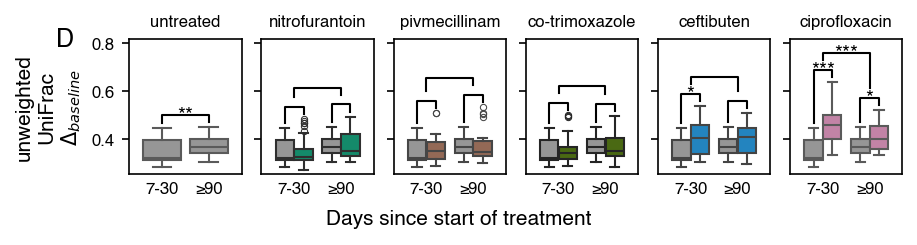

In [45]:
def _plot_beta_boxplots(figa, metric='unweighted_unifrac', letter='D'):
    """
    Helper function for beta boxplot strip
    """
    [fig, figl] = figa.subfigures(2, 1, height_ratios=[7, 1], facecolor=None)
    gs = fig.add_gridspec(1, 6)
    for abx in np.arange(6):
        if abx == 0:
            ax = fig.add_subplot(gs[abx])
        else:
            ax = fig.add_subplot(gs[abx], sharex=ax, sharey=ax)
        ap._build_beta_boxplot(ax, metric, abx, meta_r)
        ax.set_ylabel('\n'.join([clean_metrics.get(metric, metric.title()),
                                '$\\Delta_{baseline}$']),
                      size=10)
        ax.xaxis.set_tick_params(bottom=False, labelbottom=True, top=False, 
                                  labeltop=False, length=0, labelsize=8)
        ax.yaxis.set_tick_params(left=True, labelleft=(abx == 0),
                                 right=False, labelright=False, labelsize=8)
        ax.set_title(abx_order[abx], size=8)
    ylims = ax.get_ylim()
    yscale =  np.diff(ylims)[0]
    yticks = [y for y in ax.get_yticks() if (y >= ylims[0]) & (y <= ylims[1])]
    for abx, abx_ax in enumerate(fig.axes):
        lines, plabs = ap._build_lines_abx(ylims, abx, metric, ttops.copy(), 
                                           period_pvals=period_pvals, 
                                           inter_pvals=inter_pvals)
        for ll, p_ in zip(*(lines, plabs)):
            abx_ax.plot(*ll, color='k', linestyle='-', linewidth=1)
            abx_ax.text(x=np.mean(ll[0]), y=np.max(ll[1]), s=p_, 
                        ha='center', va='center', size=10)
        abx_ax.set_ylim(ylims[0], ylims[1] + 0.4 * yscale)
    fig.axes[0].text(fig.axes[0].get_xlim()[0] - np.diff(fig.axes[0].get_xlim()) * 0.65,
                     fig.axes[0].get_ylim()[1],
                     letter, size=12, ha='left', va='center')

    # Adds a ylabel figure
    ap._add_labelfig(figl, 'Days since start of treatment')
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(6, 1.5))

_plot_beta_boxplots(fig)

# Final Figure

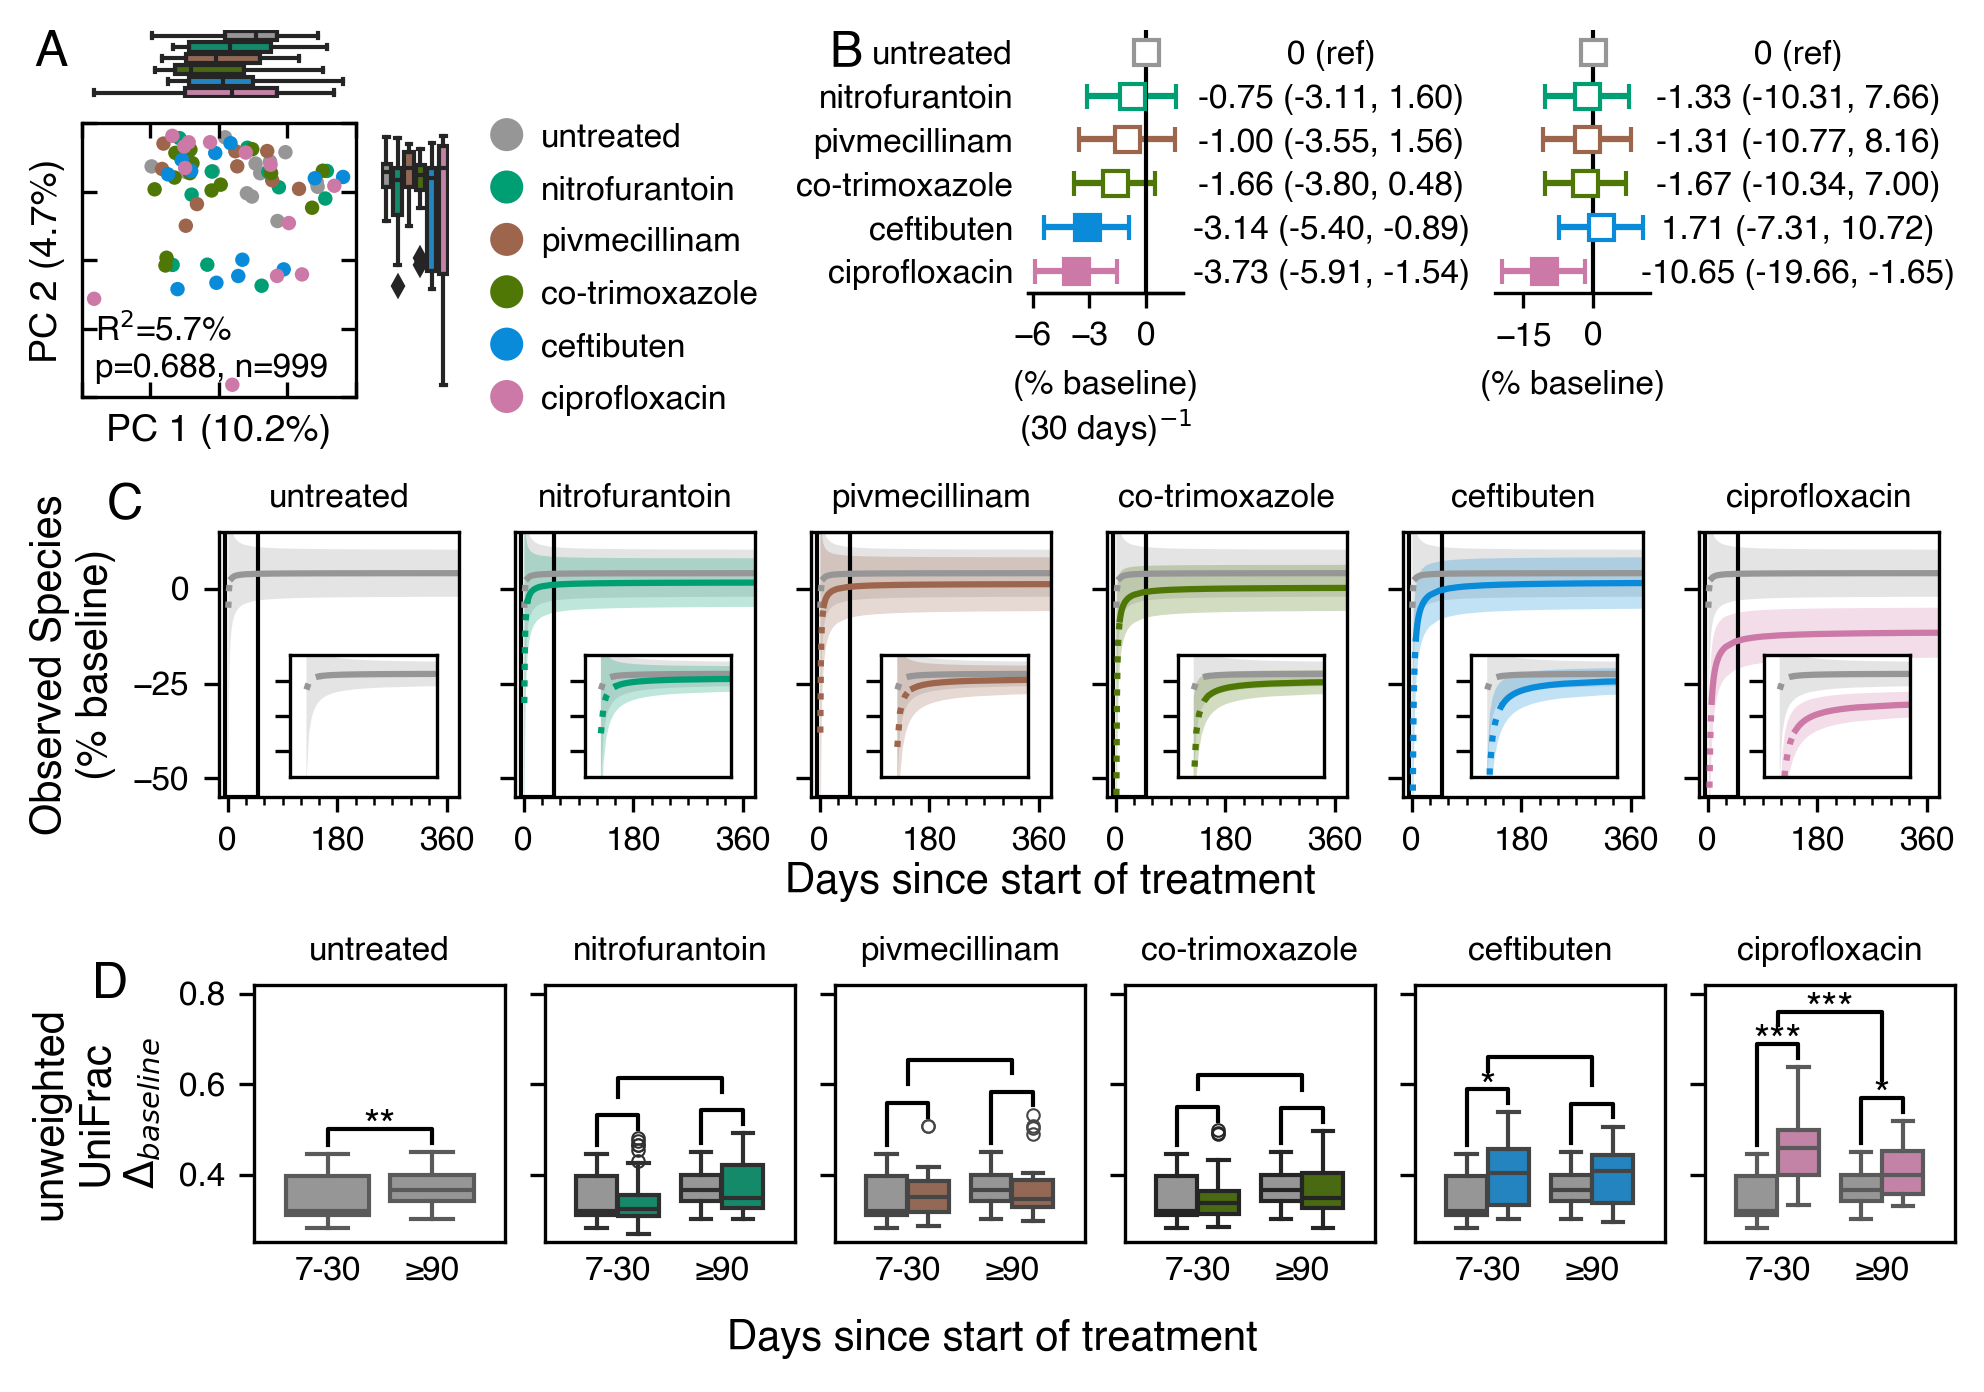

In [46]:
fig = plt.figure(dpi=300, constrained_layout=True, 
                 figsize=(6.5,  (1.5 + 1.5 + 1.5)), 
                 facecolor='w')
[fig0, fig1, fig2] = fig.subfigures(3, 1, height_ratios=[1.5, 1.5, 1.5], facecolor='None')
# [fig01, fig01l, fig02, fig03] = fig0.subfigures(1, 4, width_ratios=[1.5, 1, 1.25, 6-(1.5 + 1 + 1.25)], facecolor='None')
[fig01, fig01l, fig02] = fig0.subfigures(1, 3, width_ratios=[1.5, 1, 4], facecolor='None')

make_bl_ordination(fig01, 'uu0', 'uu1', 'unweighted_unifrac', 'full')
_make_legend(fig01l)
_build_baseline(fig02)
# plot_compare_boxplot(fig02, 'unweighted_unfirac', 'B')
# # _label_panel(fig02, 'within part')
# _label_panel(fig03, '???\nThis is worse')
# # _label_panel(fig1, 'Alpha traces')
ap.plot_alpha_curve_row(fig1, 'observed_features', sub_data, label='C')
_plot_beta_boxplots(fig2)

**Figure 2. Changes in the microbiome following antibiotic treatment.**  (A) Principal Coordinates projection of unweighted UniFrac distance between samples by treatment at group at baseline. Marginal axes show the distribution of samples along each principal component (PC) and are labeled with variance explained. The axis is labeled with the variance explained by treatment group at baseline based on an Adonis adjusted for extraction plate, and participant age, sex, and vegetarian diet. (B, C) The recovery in observed Species alpha diversity within a participant following antibiotic treatment. Panel (B) parameterizes the recovery model show (left) the rate of recovery and (right) the new steady state baseline as a percent of the pre-treatment diversity. The data was modeling using a linear mixed effect model, for sample extraction plate, difference in sequencing depth from baseline sample, and sample collection after travel outside North America or Europe. Filled points indicate a statistically significant change compared to the untreated group. (C) The estimated rate of recovery over the treatment period. For all treatment groups, the untreated group is shown in gray as a comparison. Solid lines indicate a period modeled based on actual data; dashed lines extend beyond the modeled timeframe. The shaded area shows the 95% confidence interval for the estimate. Inset boxes show the recovery in the first 45 days. (D) The change in unweighted UniFrac distance following treatment over early (7-30 days) and late (≥90 days) treatment periods. Significance markers on boxes reflect differences identified in a linear mixed effect model for distance from baseline within the period, adjusted for difference in sequencing depth form baseline, extraction plate, and sample collection after travel outside North America or Europe. *p < 0.05, **p < 0.01, ***p < 0.001.